# Clase 9 · Clustering jerárquico y DBSCAN

**INF-396 Introducción a la Ciencia de Datos** · Universidad Técnica Federico Santa María · viernes 6 de noviembre de 2026

**Qué hacemos hoy.** Dos métodos de clustering más, después de k-means. El clustering jerárquico no pide el número de grupos y entrega un dendrograma con todas las particiones. DBSCAN agrupa por densidad, encuentra grupos de cualquier forma y separa el ruido. Las lecturas son la sección 10.3.2 de James, Witten, Hastie y Tibshirani (2013) y el artículo de DBSCAN de Ester, Kriegel, Sander y Xu (1996).

## 1. Preparación

Además de lo de siempre, de **scikit-learn** se usan `AgglomerativeClustering` (el clustering jerárquico) y `DBSCAN`. scikit-learn no dibuja el dendrograma, así que para eso se usan `linkage` y `dendrogram` de **SciPy**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy: distancias y clustering jerárquico
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# scikit-learn: estandarizar, los métodos de hoy y datos simulados
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.datasets import make_moons

sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = "retina"
pd.options.display.float_format = "{:.3f}".format

In [2]:
# Datos locales del repositorio clonado
BASE = "datos/"
# Alternativa por URL, si no tiene el repositorio clonado:
# BASE = "https://raw.githubusercontent.com/daniopitz/cienciadatos/main/datos/"

## 2. Clustering jerárquico de los pingüinos

**Objetivo:** agrupar los 342 pingüinos de la clase 08 sin usar la especie y comparar después.

Como en k-means, se estandarizan las cuatro medidas, para que la masa (en gramos) no pese más que el pico (en milímetros).

In [3]:
pinguinos = pd.read_csv(BASE + "clase08/pinguinos_palmer.csv")
medidas = ["largo_pico_mm", "alto_pico_mm", "largo_aleta_mm", "masa_g"]
pinguinos = pinguinos.dropna(subset=medidas).reset_index(drop=True)
Z = StandardScaler().fit_transform(pinguinos[medidas])
print(pinguinos.shape)

(342, 8)


**Los grupos con scikit-learn.** `AgglomerativeClustering` hace el clustering jerárquico aglomerativo. Recibe el número de grupos en `n_clusters` y el enlace en `linkage`, que puede ser `"complete"`, `"single"`, `"average"` o `"ward"` (el valor por omisión). Con tres grupos y el enlace completo, 328 de los 342 pingüinos quedan en el grupo de su especie. Los 14 que no calzan son barbijos que quedan junto a los Adelia.

In [4]:
jerarquico = AgglomerativeClustering(n_clusters=3, linkage="complete")
pinguinos["jerarquico"] = jerarquico.fit_predict(Z)
pd.crosstab(pinguinos["especie"], pinguinos["jerarquico"])

jerarquico,0,1,2
especie,,,
Adelia,0,151,0
Barbijo,0,14,54
Papúa,123,0,0


**El dendrograma con SciPy.** `linkage` hace las mismas uniones y recibe el enlace en `method`, y `dendrogram` las dibuja. El corte a altura 5 da los tres grupos de arriba.

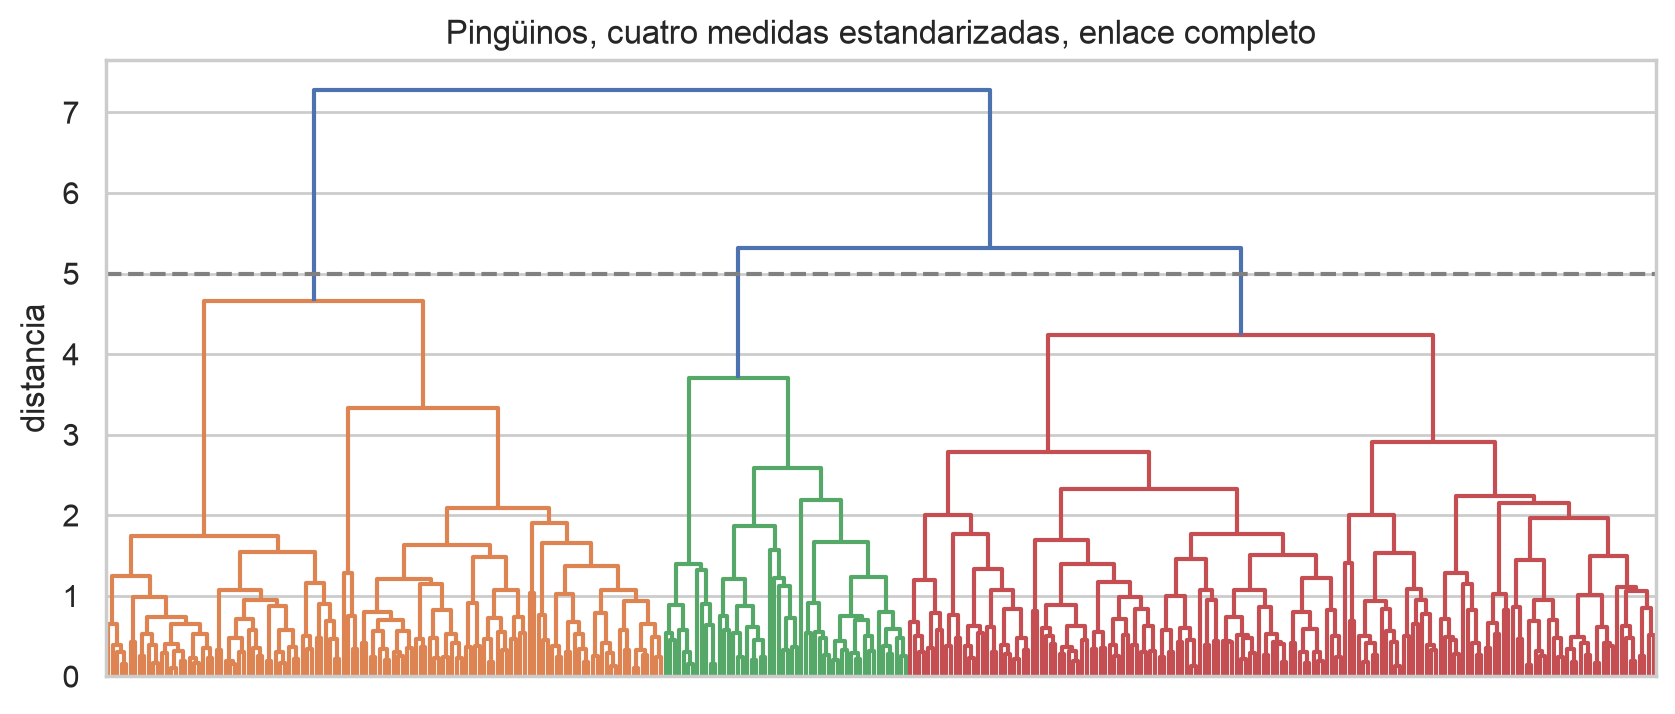

In [5]:
L = linkage(Z, method="complete")
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(L, ax=ax, no_labels=True, color_threshold=5)  # colorea cada grupo del corte a altura 5
ax.axhline(5, color="gray", ls="--")
ax.set_ylabel("distancia")
ax.set_title("Pingüinos, cuatro medidas estandarizadas, enlace completo")
plt.show()

**Efecto del enlace.** Con scikit-learn basta cambiar el parámetro `linkage`. Con el enlace promedio y el simple, el corte en tres grupos deja un grupo casi vacío, porque el simple tiende a encadenar observaciones en un grupo grande (James et al., 2013). Ward, el valor por omisión, da grupos parecidos a los del completo.

In [6]:
for enlace in ["complete", "average", "single", "ward"]:
    modelo = AgglomerativeClustering(n_clusters=3, linkage=enlace)
    grupos = modelo.fit_predict(Z)
    print(f"{enlace:>8}: tamaños de los grupos", np.bincount(grupos))

complete: tamaños de los grupos [123 165  54]
 average: tamaños de los grupos [219 119   4]
  single: tamaños de los grupos [218   1 123]
    ward: tamaños de los grupos [162 123  57]


**k-means con las mismas medidas**, para comparar. Como en la clase 08, con las cuatro medidas estandarizadas.

In [7]:
pinguinos["kmeans"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
pd.crosstab(pinguinos["especie"], pinguinos["kmeans"])

kmeans,0,1,2
especie,,,
Adelia,127,0,24
Barbijo,5,0,63
Papúa,0,123,0


**Los grupos en el plano de PCA.** Con cuatro medidas no se puede dibujar cada pingüino directamente. Las dos primeras componentes principales (clase 08) resumen las cuatro medidas estandarizadas en un plano. El primer panel muestra la especie, y los otros dos, los grupos de k-means y del jerárquico. Los números de los grupos son arbitrarios, así que, para comparar, cada grupo se pinta con el color de la especie más común en él. Los puntos con otro color que en el primer panel son los pingüinos que quedaron con otra especie.

In [8]:
pca = PCA(n_components=2).fit(Z)
componentes = pca.transform(Z)
pinguinos["pc1"] = componentes[:, 0]
pinguinos["pc2"] = componentes[:, 1]
print("variación explicada por las dos componentes:", pca.explained_variance_ratio_.sum().round(3))

variación explicada por las dos componentes: 0.882


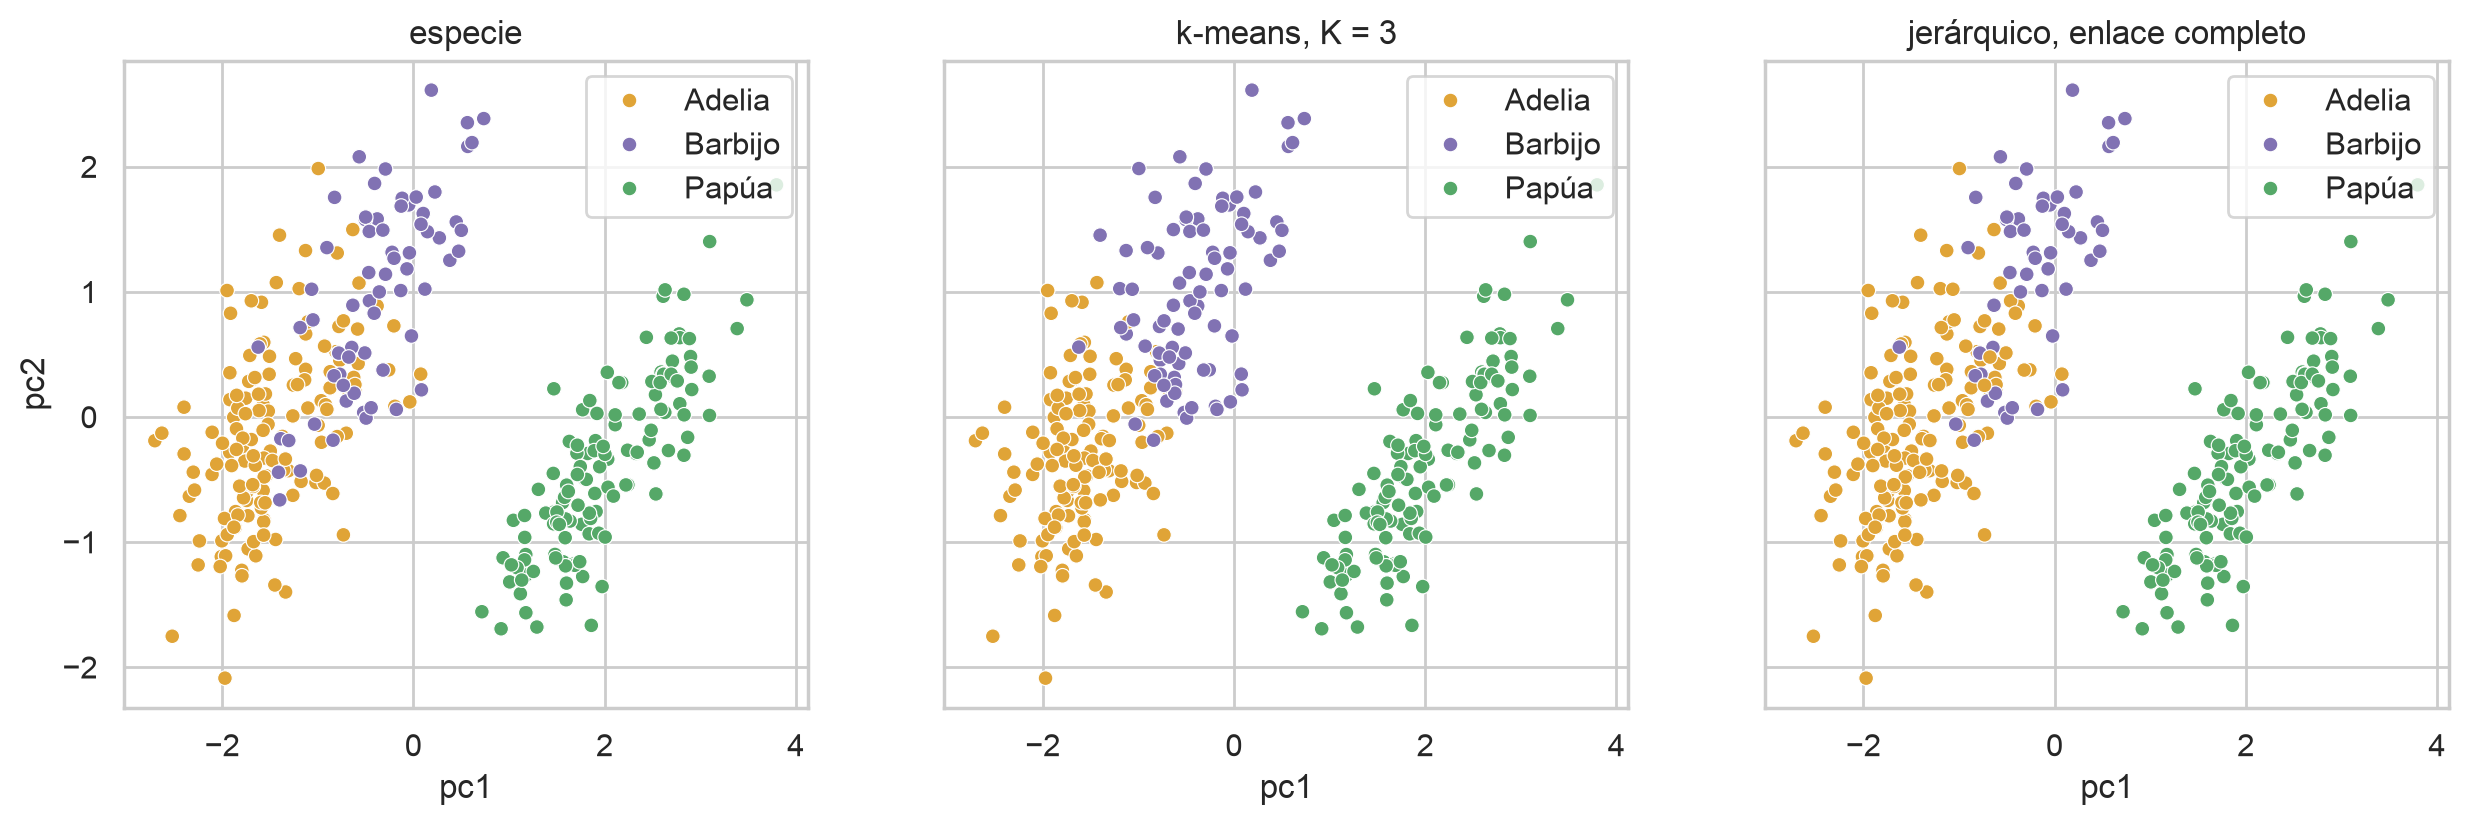

In [9]:
# cada grupo toma el nombre de la especie más común en él, solo para pintarlo
for metodo in ["kmeans", "jerarquico"]:
    mas_comun = pinguinos.groupby(metodo)["especie"].agg(lambda s: s.mode()[0])
    pinguinos[metodo + "_color"] = pinguinos[metodo].map(mas_comun)

colores = {"Adelia": "#E0A437", "Barbijo": "#8172B3", "Papúa": "#55A868"}
titulos = {"especie": "especie", "kmeans_color": "k-means, K = 3",
           "jerarquico_color": "jerárquico, enlace completo"}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, columna in zip(axs, titulos):
    sns.scatterplot(data=pinguinos, x="pc1", y="pc2", hue=columna, palette=colores,
                    hue_order=list(colores), s=28, ax=ax)
    ax.set_title(titulos[columna])
    ax.legend(title="")
plt.show()

**¿Cuál es mejor, sin mirar la especie?** En general no se tiene una respuesta con qué comparar. Una medida que no la necesita es el coeficiente de *silhouette*. Para cada observación, a es la distancia promedio a las observaciones de su propio grupo y b la distancia promedio a las del grupo vecino más cercano. Su coeficiente de silhouette es s = (b − a) / máx(a, b). Cerca de 1, la observación está bien puesta en su grupo; cerca de 0, está en la frontera entre dos grupos; negativa, estaría mejor en el otro. `silhouette_score` entrega el promedio de todas las observaciones. Más alto es mejor.

**El coeficiente de cada pingüino.** `silhouette_samples` entrega s(i) para cada observación, como la última columna de la tabla de la slide del ejemplo. Se guarda en una columna por método.

In [10]:
pinguinos["s_kmeans"] = silhouette_samples(Z, pinguinos["kmeans"])
pinguinos["s_jerarquico"] = silhouette_samples(Z, pinguinos["jerarquico"])
pinguinos[["especie", "kmeans", "s_kmeans", "jerarquico", "s_jerarquico"]].sample(6, random_state=2)

,especie,kmeans,s_kmeans,jerarquico,s_jerarquico
262,Papúa,1,0.560,0,0.560
70,Adelia,0,0.431,1,0.501
69,Adelia,0,0.526,1,0.532
98,Adelia,2,0.041,1,0.185
7,Adelia,0,0.553,1,0.544
244,Papúa,1,0.590,0,0.590


**El coeficiente del agrupamiento** es el promedio de la columna, S. Es lo mismo que entrega `silhouette_score`. Más alto es mejor.

In [11]:
print("S de k-means:   ", round(pinguinos["s_kmeans"].mean(), 3))
print("S del jerárquico:", round(pinguinos["s_jerarquico"].mean(), 3))
print("con silhouette_score:", round(silhouette_score(Z, pinguinos["kmeans"]), 3),
      round(silhouette_score(Z, pinguinos["jerarquico"]), 3))

S de k-means:    0.447
S del jerárquico: 0.452
con silhouette_score: 0.447 0.452


**Con otros números de grupos.** Se repite el cálculo con 2, 3 y 4 grupos.

In [12]:
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    jc = AgglomerativeClustering(n_clusters=k, linkage="complete").fit_predict(Z)
    print(f"K = {k}: k-means {silhouette_score(Z, km):.3f}, jerárquico {silhouette_score(Z, jc):.3f}")

K = 2: k-means 0.532, jerárquico 0.532
K = 3: k-means 0.447, jerárquico 0.452
K = 4: k-means 0.400, jerárquico 0.394


El valor más alto, 0,532, es con dos grupos y cualquiera de los dos métodos, aunque hay tres especies, porque lo más separado de los datos es papúa contra el resto, ya que Adelia y barbijo se tocan. Con tres grupos, el jerárquico gana por 0,005, un empate en la práctica. Una medida como esta dice qué tan compactos y separados quedan los grupos, no si son los verdaderos. Por eso los grupos se validan también viendo si tienen sentido para el problema (James et al., 2013, sección 10.3.3).

## 3. DBSCAN

**Objetivo:** agrupar por densidad, con grupos que no son compactos.

Se simulan dos medias lunas de 150 puntos cada una y se agregan 12 puntos sueltos. Todo va a un DataFrame, `lunas`, con las coordenadas `x1` y `x2` y la columna `origen`, que dice de qué luna viene cada punto o si es suelto. `origen` no se usa para agrupar, solo para revisar después. Cada método deja sus grupos en una columna nueva.

In [13]:
X_lunas, y_lunas = make_moons(300, noise=0.07, random_state=0)
rng = np.random.default_rng(3)
sueltos = rng.uniform([-1.4, -0.9], [2.4, 1.4], size=(12, 2))
lunas = pd.DataFrame(np.vstack([X_lunas, sueltos]), columns=["x1", "x2"])
origen = ["luna 1" if y == 0 else "luna 2" for y in y_lunas]
lunas["origen"] = origen + ["suelto"] * 12
X = lunas[["x1", "x2"]]
lunas.sample(5, random_state=0)

,x1,x2,origen
65,0.916,-0.415,luna 2
225,0.080,-0.026,luna 2
188,0.928,-0.483,luna 2
200,1.530,-0.217,luna 2
108,2.032,0.253,luna 2


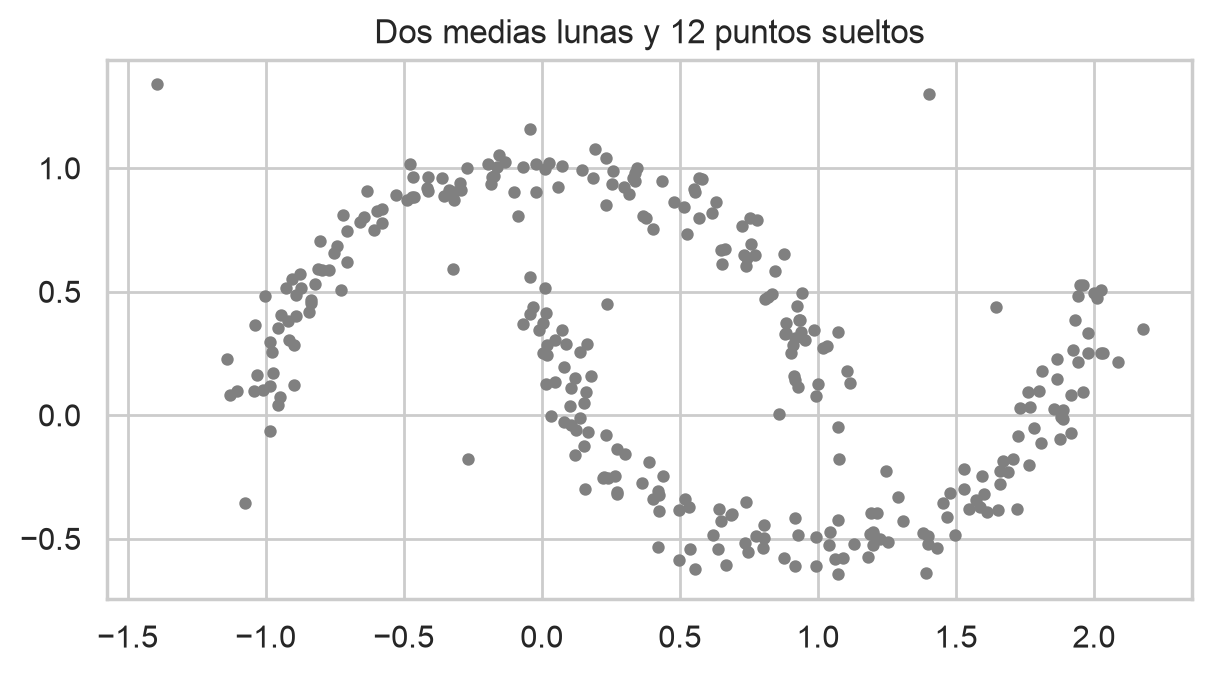

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(lunas["x1"], lunas["x2"], s=12, color="gray")
ax.set_title("Dos medias lunas y 12 puntos sueltos")
plt.show()

**k-means y el jerárquico con enlace completo** cortan las lunas, porque buscan grupos compactos. Cada uno deja sus grupos en una columna.

In [15]:
lunas["kmeans"] = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
lunas["jerarquico"] = AgglomerativeClustering(n_clusters=2, linkage="complete").fit_predict(X)
pd.crosstab(lunas["origen"], lunas["kmeans"])

kmeans,0,1
origen,,
luna 1,110,40
luna 2,40,110
suelto,7,5


In [16]:
pd.crosstab(lunas["origen"], lunas["jerarquico"])

jerarquico,0,1
origen,,
luna 1,69,81
luna 2,118,32
suelto,5,7


**DBSCAN** tiene dos parámetros, el radio `eps` (ε) y el mínimo de puntos `min_samples` (m), que cuenta al propio punto (Ester et al., 1996). En `labels_`, el ruido es −1. Con ε = 0,2 y m = 5, cada luna queda en un grupo y 6 de los puntos sueltos quedan como ruido.

In [17]:
db = DBSCAN(eps=0.2, min_samples=5).fit(X)
lunas["dbscan"] = db.labels_
pd.crosstab(lunas["origen"], lunas["dbscan"])

dbscan,-1,0,1
origen,,,
luna 1,0,1,149
luna 2,0,150,0
suelto,6,5,1


**Los tres métodos en un gráfico.** Cada panel colorea los puntos según la columna de un método. En gris, el ruido de DBSCAN.

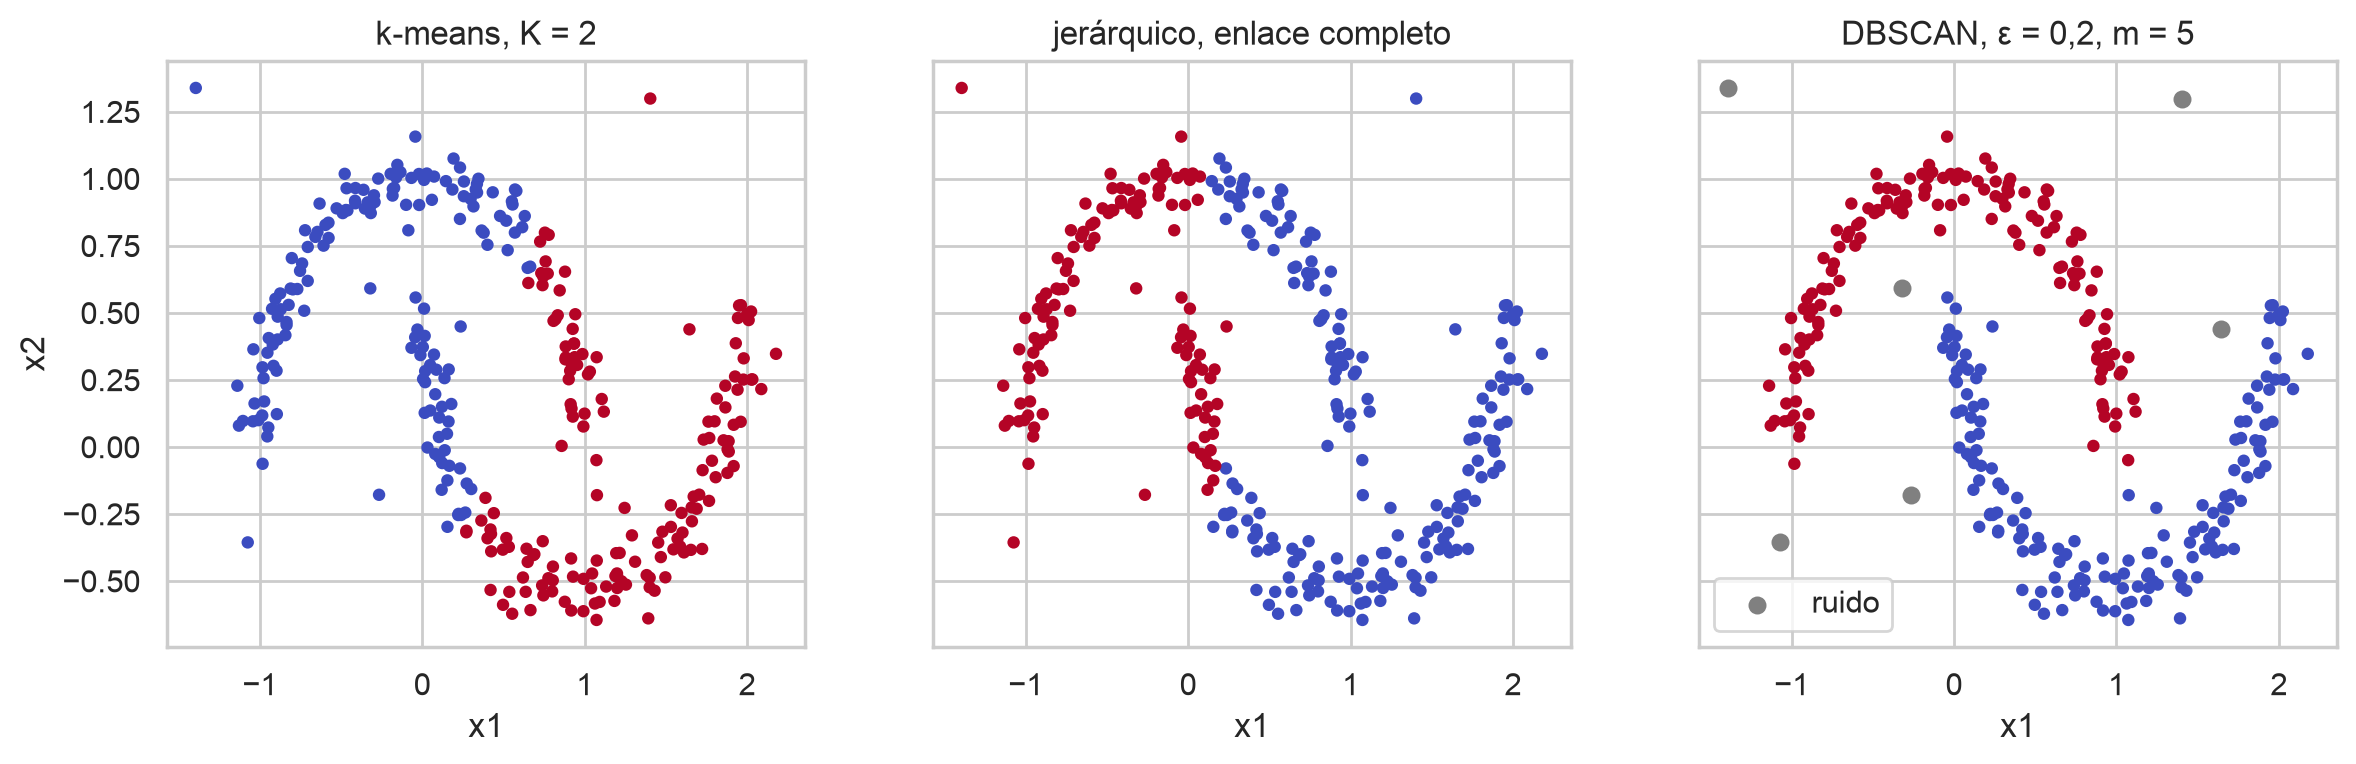

In [18]:
titulos = {"kmeans": "k-means, K = 2", "jerarquico": "jerárquico, enlace completo",
           "dbscan": "DBSCAN, ε = 0,2, m = 5"}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, metodo in zip(axs, titulos):
    ruido = lunas[metodo] == -1
    ax.scatter(lunas.loc[~ruido, "x1"], lunas.loc[~ruido, "x2"], c=lunas.loc[~ruido, metodo],
               cmap="coolwarm", s=12)
    ax.scatter(lunas.loc[ruido, "x1"], lunas.loc[ruido, "x2"], color="gray", s=30, label="ruido")
    ax.set_title(titulos[metodo])
    ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
axs[2].legend()
plt.show()

**Comparar los tres métodos con métricas.** El coeficiente de silhouette no necesita la respuesta. Para DBSCAN se calcula sin los puntos de ruido. Como aquí las lunas son simuladas, también se puede comparar cada agrupamiento con las lunas reales (la columna `origen`) con el índice de Rand ajustado (`adjusted_rand_score`), que vale 1 si los grupos coinciden con las lunas y cerca de 0 si coinciden por azar (Hubert y Arabie, 1985). Se calcula con los 300 puntos de las lunas.

In [19]:
de_luna = lunas["origen"] != "suelto"
for metodo in ["kmeans", "jerarquico", "dbscan"]:
    sin_ruido = lunas[metodo] != -1
    s = silhouette_score(X[sin_ruido], lunas.loc[sin_ruido, metodo])
    ari = adjusted_rand_score(lunas.loc[de_luna, "origen"], lunas.loc[de_luna, metodo])
    print(f"{metodo:>10}: silhouette {s:.2f}, Rand ajustado {ari:.2f}")

    kmeans: silhouette 0.48, Rand ajustado 0.22
jerarquico: silhouette 0.44, Rand ajustado 0.10
    dbscan: silhouette 0.33, Rand ajustado 0.99


El coeficiente de silhouette prefiere k-means, que corta las lunas, y deja a DBSCAN último, aunque es el único que encuentra las lunas. Usa distancias promedio, así que en una luna alargada los puntos de una punta quedan lejos de los de la otra y a(i) sale grande. Premia los grupos compactos y redondos, lo mismo que busca k-means. Ninguna métrica es neutral, cada una trae su propia idea de qué es un buen grupo.

Las tres columnas, una al lado de la otra, para los mismos puntos.

In [20]:
lunas.sample(8, random_state=1)

,x1,x2,origen,kmeans,jerarquico,dbscan
80,-0.797,0.588,luna 1,0,1,1
267,-0.871,0.514,luna 1,0,1,1
309,1.246,-0.227,suelto,1,0,0
187,-0.632,0.908,luna 1,0,1,1
105,1.039,-0.526,luna 2,1,0,0
89,1.074,-0.423,luna 2,1,0,0
311,-0.266,-0.178,suelto,0,1,-1
225,0.080,-0.026,luna 2,0,1,0


**El radio.** Con ε muy chico las lunas se rompen en muchos grupos, y con ε muy grande el radio salta de una luna a la otra.

In [21]:
for eps in [0.1, 0.15, 0.2, 0.25, 0.3]:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    n_grupos = len(set(etiquetas) - {-1})
    n_ruido = (etiquetas == -1).sum()
    print(f"ε = {eps}: grupos = {n_grupos}, puntos de ruido = {n_ruido}")

ε = 0.1: grupos = 13, puntos de ruido = 38
ε = 0.15: grupos = 2, puntos de ruido = 9
ε = 0.2: grupos = 2, puntos de ruido = 6
ε = 0.25: grupos = 1, puntos de ruido = 6
ε = 0.3: grupos = 1, puntos de ruido = 4


---

**Próximas fechas.** El viernes 13 de noviembre se ven las máquinas de soporte vectorial (SVM). La Tarea 2 se entrega el lunes 16 de noviembre por Aula. El viernes 20 de noviembre es el Control Q4, al inicio de la clase.